# Supplementary figures

Supplementary figures, regenerated from the saved results of `OUT`:

| file | figure |
|---|---|
| `figures/paper/supplementary/figS_selection_path` | Fig. S2: every decision of the parameter selection, its rule, the free count, the objective and the rank and correlation diagnostics |
| `figures/paper/supplementary/figS_final_identifiability` | Fig. S3: singular values of the rate sensitivities (initial estimation and final model), eigenvalues of the Fisher information and correlations of the final model |
| `figures/paper/supplementary/figS_parity_stages` | Fig. S4: parity of LI fluxes and metabolites for the literature model, the initial estimation (37 free), the final model and LOOCV |
| `figures/paper/supplementary/figS_parameter_evolution` | Fig. S5: all 37 parameter values across the stages; fixed parameters show the rule that fixed them |
| `figures/paper/supplementary/figS_bootstrap_all` | Fig. S6: bootstrap distributions of the free parameters with the estimate and the 95% percentile interval |
| `figures/paper/supplementary/figS_profiles_all` | Fig. S7: re-optimised profile likelihoods of the free parameters with the 95% threshold |

Fig. S1 (the map of the central carbon metabolism of *E. coli*) is an image, not made here. The figures use the model colours of the main figures and the LaTeX font for equations.

Each uncertainty figure is coloured by its own test, in the colours of Fig. 2e and 2f: the bootstrap figure by the bootstrap verdict (practically identifiable if the percentile ratio is at most `bootstrap_ci_ratio` with an interval clear of the parameter bounds), the profile figure by the profile class (identifiable, one-sided, flat). Parameter names are coloured by type (PTS, $k_{\mathrm{cat}}$, $K$) and reactions by their colours in Fig. 2a.

Each figure is written out in full in its own cell; the panels of the multi-panel figures are written one by one. The parity and evolution figures work for any structure; the two figures with one panel per free parameter are laid out for **14 free parameters** (a 3 x 5 grid whose last cell holds the legend). If a run ends with a different number of free parameters, the check cell stops with a message and the panels have to be added or removed. Needs the outputs of `parameter_selection`, `final_fit`, `bootstrap`, `profiles`, `loocv` and `figure_data` (run order in `notebooks/README.md`).

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.METHOD["out_dir"])   # default: out_dir of settings/method.csv; relative paths are relative to the repo root

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import paper_style as S
from model.parameters import ALL_PARAMS, LI_FLUX_KEYS
from data import measured_balanced_keys
from settings import METHOD

SUPPLEMENTARY = os.path.join(OUT, "figures", "paper", "supplementary")   # the supplementary figures of the paper
os.makedirs(SUPPLEMENTARY, exist_ok=True)

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model


In [2]:
needed = {
    "stage0/theta_full.csv": "parameter_selection",
    "stage0/pred_insample_predicted.csv": "parameter_selection",
    "stage0/stage_row.json": "parameter_selection",
    "reduction/fixing_log.csv": "parameter_selection",
    "reduction/iterations.csv": "parameter_selection",
    "reduction/structural_spectrum.csv": "parameter_selection",
    "final/final_summary.json": "final_fit",
    "final/final_structural_spectrum.csv": "final_fit",
    "final/final_singular_spectrum.csv": "final_fit",
    "final/final_correlation.csv": "final_fit",
    "final/final_structure.csv": "final_fit",
    "final/theta_full.csv": "final_fit",
    "final/pred_insample_predicted.csv": "final_fit",
    "final/pred_insample_real.csv": "final_fit",
    "bootstrap/bootstrap_theta.csv": "bootstrap",
    "bootstrap/bootstrap_summary.csv": "bootstrap",
    "profiles/profiles_all.csv": "profiles",
    "profiles/profile_summary.csv": "profiles",
    "profiles/profile_thresholds.json": "profiles",
    "loocv/loocv_pred.csv": "loocv",
    "paper_figs_data/stage_metrics.csv": "figure_data (after loocv)",
    "paper_figs_data/y_literature_inner.csv": "figure_data (HK_RUN=1)",
}

absent = []
for file_name, step in needed.items():
    if not os.path.exists(os.path.join(OUT, file_name)):
        absent.append("  %-45s written by %s" % (file_name, step))

if absent:
    raise FileNotFoundError("missing results of preceding steps (run them first):\n" + "\n".join(absent))

def path(*parts):
    return os.path.join(OUT, *parts)

final_structure = pd.read_csv(path("final", "final_structure.csv"))
bootstrap_summary = pd.read_csv(path("bootstrap", "bootstrap_summary.csv"), index_col=0)
profile_summary = pd.read_csv(path("profiles", "profile_summary.csv"), index_col=0)
free_in_table = set(final_structure.loc[final_structure["status"] == "free", "param"])
FREE = [p for p in ALL_PARAMS if p in free_in_table]
CLASS_OF = S.classes_of_free(final_structure, bootstrap_summary, profile_summary)
literature = pd.read_csv(os.path.join(REPO, "Data", "theta_init_sampled.csv"), index_col=0)["value"]
th0 = pd.read_csv(path("stage0", "theta_full.csv"), index_col=0)["value"]
thf = pd.read_csv(path("final", "theta_full.csv"), index_col=0)["value"]
stage_metrics = pd.read_csv(path("paper_figs_data", "stage_metrics.csv"), index_col=0)
print("free (%d): %s" % (len(FREE), FREE))
print("classes:", CLASS_OF)

free (14): ['v_max_1', 'Ks_g6p_pgi', 'kcat_f_2', 'kcat_f_3', 'Ks_fbp_4', 'kcat_f_4', 'kcat_f_5', 'kcat_f_6', 'kcat_f_7', 'Ks_adp_7', 'kcat_f_8', 'Ks_3pg_8', 'kcat_f_9', 'Ks_2pg_9']
classes: {'v_max_1': 'not identifiable', 'Ks_g6p_pgi': 'not identifiable', 'kcat_f_2': 'not identifiable', 'kcat_f_3': 'not identifiable', 'Ks_fbp_4': 'not identifiable', 'kcat_f_4': 'practically identifiable', 'kcat_f_5': 'not identifiable', 'kcat_f_6': 'practically identifiable', 'kcat_f_7': 'not identifiable', 'Ks_adp_7': 'not identifiable', 'kcat_f_8': 'practically identifiable', 'Ks_3pg_8': 'not identifiable', 'kcat_f_9': 'practically identifiable', 'Ks_2pg_9': 'not identifiable'}


In [3]:
# ---- colours and helpers shared by the figures (the colours of the main figures) ----
TYPE_COLOR = {"PTS": "#AA4499", "kcat": "#2e7d32", "K": "#2b2a8c"}   # parameter types, as the labels of Fig. 2a and 2b
TYPE_NAME = {"PTS": "PTS", "kcat": "$k_{\\mathrm{cat}}$", "K": "$K$"}
RULE_COLOR = {"structural_zero": "#6a4a8a", "svd": "#c28a00", "correlation": "#c0392b"}   # the rule that fixed a parameter
C_IDENTIFIABLE = "#138D75"       # identifiable / practically identifiable, as in Fig. 2e and 2f
C_ONE_SIDED = "#7D3C98"
C_NOT_IDENTIFIABLE = "#D35E98"   # not identifiable / flat
C_LIT = "#ADB6B6"
C_INITIAL = "#7E9CC8"
C_FINAL = "#00468B"
MINUS = chr(0x2212)   # true minus sign for negative numbers in texts

def type_of(param):
    """PTS, kcat or K: the type of a parameter, as in Fig. 2b."""
    if param.startswith("kcat_f_"):
        return "kcat"
    if S.reaction_of(param) == 1:
        return "PTS"
    return "K"

def lighter(hex_color, amount):
    """Blend a colour towards white: amount 0 = the colour, 1 = white."""
    rgb = np.array([int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]) / 255.0
    return tuple(rgb + (1.0 - rgb) * amount)

def relative_luminance(hex_color):
    """Relative luminance (WCAG) of a colour given as '#rrggbb'."""
    rgb = np.array([int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]) / 255.0
    linear = np.where(rgb <= 0.03928, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    return float(0.2126 * linear[0] + 0.7152 * linear[1] + 0.0722 * linear[2])

def text_colour_on(background):
    """White or ink, whichever has the higher contrast on the background (names in the reaction headers)."""
    contrast_white = 1.05 / (relative_luminance(background) + 0.05)
    contrast_ink = (relative_luminance(background) + 0.05) / (relative_luminance(S.INK) + 0.05)
    if contrast_white >= contrast_ink:
        return "white"
    return S.INK

## Fig. S2: the parameter selection, decision by decision

The decisions in order: the structural phase (S1, S2, ...: one structural zero each, all taken on the initial estimation and refitted once after the last one) and then one practical iteration per decision (numbered as in `reduction/iterations.csv`), ending with the analysis that finds the free set identifiable (final). a) the parameter fixed by each decision, by rule (names coloured by parameter type); the dotted lines separate the two phases and, lighter, the stages of the practical phase (runs of decisions taken by the same rule: rank deficiency of $\mathbf{F}$, i.e. the smallest singular value of $\mathbf{G}$, then correlation), named above the panel; b) number of free parameters after each decision; c) objective of the current fit after each decision, with the objective of the final model plus the 95% likelihood-ratio threshold (shaded); d) smallest singular value ratio $\sigma_{\min}/\sigma_1$ of the stacked rate sensitivities $\mathbf{R}$ before each structural decision (threshold $\epsilon_1$ = `structural_tol`; the open marker is the check that ends the structural phase) and smallest eigenvalue ratio $\lambda_{\min}/\lambda_{\max}$ of the Fisher information $\mathbf{F}$ at each practical iteration (threshold $\epsilon_2$ = `rank_tol`$^2$, since `rank_tol` bounds the singular values of $J$ and $\mathbf{F} = J^\top J$); e) largest $|r|$ among the free parameters at the practical iterations with a full-rank $\mathbf{F}$ (threshold `corr_threshold`).

In [4]:
fix_log = pd.read_csv(path("reduction", "fixing_log.csv"))
iterations = pd.read_csv(path("reduction", "iterations.csv"))
stage_row = json.load(open(path("stage0", "stage_row.json")))
final_summary = json.load(open(path("final", "final_summary.json")))

# ---- decisions in order: the structural step (S1, S2, ...) and one practical iteration per decision ----
decisions = fix_log.reset_index(drop=True)
n_decisions = len(decisions)
stop_position = n_decisions + 1
labels = ["initial"]
n_structural_decisions = 0
for _, row in decisions.iterrows():
    if row["stage"] == "structural":
        n_structural_decisions += 1
        labels.append("S%d" % n_structural_decisions)
    else:
        labels.append("%d" % row["iter"])

labels.append("final")
positions = np.arange(len(labels))
decisions["position"] = np.arange(1, n_decisions + 1)

# ---- (b) free parameters after each decision ----
n_free_path = [len(ALL_PARAMS)]
for _, row in decisions.iterrows():
    if row["action"] == "fixed":
        n_free_path.append(n_free_path[-1] - 1)
    else:
        n_free_path.append(n_free_path[-1])

n_free_path.append(len(FREE))

# ---- (c) objective of the current fit after each decision (the structural fixes are refitted once, after the last one) ----
objective_path = [float(stage_row["obj"])]
for i, row in decisions.iterrows():
    if row["stage"] == "structural" and i + 1 < n_structural_decisions:
        objective_path.append(float(row["obj_before"]))
    elif np.isfinite(row["obj_after"]):
        objective_path.append(float(row["obj_after"]))
    else:
        objective_path.append(float(row["obj_before"]))

objective_path.append(float(final_summary["obj"]))

# ---- (d) smallest singular value ratio of the stacked rate sensitivities before each structural decision ----
structural_spectrum = pd.read_csv(path("reduction", "structural_spectrum.csv"), index_col=0)
structural_x = []
structural_ratio = []
for j, column in enumerate(structural_spectrum.columns):
    if j < n_structural_decisions:
        structural_x.append(j + 1)
    else:
        structural_x.append(n_structural_decisions + 0.5)
    structural_ratio.append(float(structural_spectrum[column].dropna().iloc[-1]))

structural_x = np.array(structural_x)
structural_ratio = np.array(structural_ratio)
is_decision = structural_x == np.round(structural_x)

# ---- (d, e) practical iterations: eigenvalue ratio of F (the squared singular value ratio of J) and the largest |r| ----
practical_position = {}
for _, row in decisions.iterrows():
    if row["stage"] == "practical":
        practical_position[int(row["iter"])] = int(row["position"])

iteration_x = []
for it in iterations["iter"]:
    iteration_x.append(practical_position.get(int(it), stop_position))

iteration_x = np.array(iteration_x)
eigen_ratio = iterations["sigma_ratio_min"].to_numpy(float) ** 2
max_abs_r = iterations["max_abs_r"].to_numpy(float)
has_r = np.isfinite(max_abs_r)

RULES = [("structural_zero", "structural zero of $\\mathbf{R}$", "s"),
         ("svd", "rank deficiency of $\\mathbf{F}$", "o"),
         ("correlation", "correlation $|r| > %g$" % METHOD["corr_threshold"], "D")]
# ---- stages of the practical phase: runs of consecutive practical decisions taken by the same rule ----
practical_stages = []   # [first position, last position, rule]
for _, row in decisions[decisions["stage"] == "practical"].iterrows():
    if len(practical_stages) > 0 and practical_stages[-1][2] == row["rule"]:
        practical_stages[-1][1] = int(row["position"])
    else:
        practical_stages.append([int(row["position"]), int(row["position"]), row["rule"]])

STAGE_NAME = {"svd": "rank deficiency of $\\mathbf{F}$ (smallest $\\sigma$ of $\\mathbf{G}$)", "correlation": "$|r| > %g$" % METHOD["corr_threshold"]}
print("decisions:", labels)
print("practical stages:", practical_stages)
print("free count:", n_free_path)

decisions: ['initial', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', 'final']
practical stages: [[9, 22, 'svd'], [23, 23, 'correlation']]
free count: [37, 36, 35, 34, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 17, 16, 15, 14, 14]


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


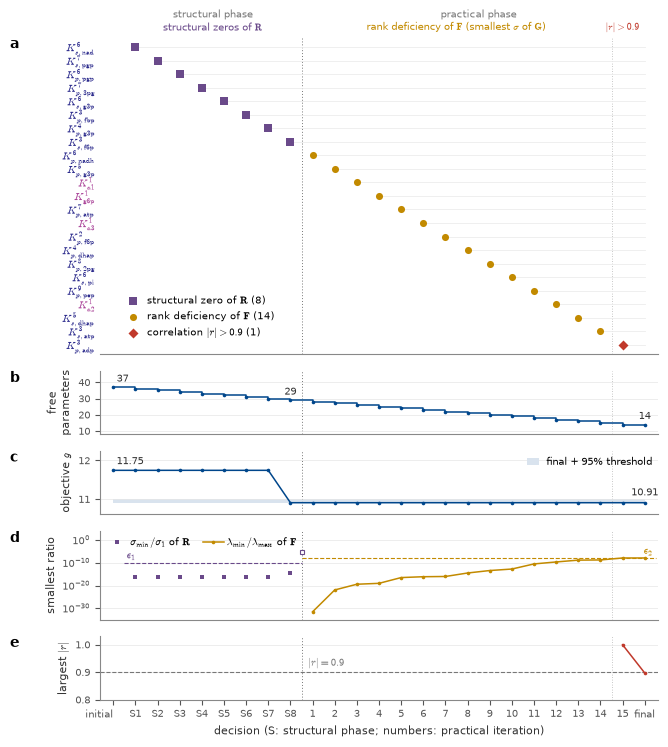

In [5]:
plt.rcdefaults()
plt.rcParams.update(S.RC)
plt.rcParams.update({"mathtext.fontset": "cm"})   # equations in the LaTeX font, as in the main figures

EPS1 = METHOD["structural_tol"]
EPS2 = METHOD["rank_tol"] ** 2   # rank_tol bounds sigma of J; the eigenvalues of F = J^T J are the squares
LINE_W = 1.1
DOT = 2.6
structural_end = n_structural_decisions + 0.5   # the divider between the two phases

fig, (ax_a, ax_b, ax_c, ax_d, ax_e) = plt.subplots(5, 1, figsize=(7.2, 8.6), sharex=True, gridspec_kw={"height_ratios": [5.0, 1.0, 1.0, 1.4, 1.0], "hspace": 0.14})

# ---- (a) parameter fixed by each decision, by rule; the light line marks it fixed from then on ----
for _, row in decisions.iterrows():
    ax_a.plot([row["position"], stop_position], [row["position"] - 1, row["position"] - 1], color="#ececec", lw=0.6, zorder=1)

for rule, rule_label, marker in RULES:
    group = decisions[(decisions["rule"] == rule) & (decisions["action"] == "fixed")]
    if len(group) > 0:
        ax_a.scatter(group["position"], group["position"] - 1, s=26, c=RULE_COLOR[rule], marker=marker, lw=0, zorder=3, label="%s (%d)" % (rule_label, len(group)))

kept_rows = decisions[decisions["action"] == "kept_free"]
if len(kept_rows) > 0:
    ax_a.scatter(kept_rows["position"], kept_rows["position"] - 1, s=26, facecolors="white", edgecolors=S.INK, marker="o", zorder=3, label="kept free by design (%d)" % len(kept_rows))

ax_a.set_yticks(decisions["position"] - 1)
ax_a.set_yticklabels([S.label(p) for p in decisions["param"]], fontsize=7.5)
for tick, p in zip(ax_a.get_yticklabels(), decisions["param"]):
    tick.set_color(TYPE_COLOR[type_of(p)])

ax_a.set_ylim(n_decisions - 0.3, -0.7)
ax_a.tick_params(axis="y", length=0)
ax_a.spines["left"].set_visible(False)
# phases on the top row, the stages of the practical phase (one rule each) under it, in the colours of their rules
ax_a.text(structural_end / 2 + 0.25, -2.0, "structural phase", ha="center", va="bottom", fontsize=7.5, color=S.MUTED)
ax_a.text((structural_end + stop_position + 0.5) / 2, -2.0, "practical phase", ha="center", va="bottom", fontsize=7.5, color=S.MUTED)
ax_a.text(structural_end / 2 + 0.25, -1.0, "structural zeros of $\\mathbf{R}$", ha="center", va="bottom", fontsize=7, color=RULE_COLOR["structural_zero"])
for first, last, rule in practical_stages:
    ax_a.text((first + last) / 2, -1.0, STAGE_NAME[rule], ha="center", va="bottom", fontsize=7, color=RULE_COLOR[rule])
ax_a.legend(loc="lower left", bbox_to_anchor=(0.03, 0.03), frameon=False, fontsize=7.5, handletextpad=0.3, labelspacing=0.5, borderaxespad=0.2)   # the empty corner under the structural phase

# ---- (b) number of free parameters ----
ax_b.step(positions, n_free_path, where="post", color=C_FINAL, lw=LINE_W)
ax_b.plot(positions, n_free_path, "o", color=C_FINAL, ms=DOT, mew=0)
ax_b.text(0.15, n_free_path[0] + 2, "%d" % n_free_path[0], ha="left", va="bottom", fontsize=7, color=S.INK)
ax_b.text(n_structural_decisions, n_free_path[n_structural_decisions] + 2, "%d" % n_free_path[n_structural_decisions], ha="center", va="bottom", fontsize=7, color=S.INK)
ax_b.text(stop_position, n_free_path[-1] + 2, "%d" % n_free_path[-1], ha="center", va="bottom", fontsize=7, color=S.INK)
ax_b.set_ylim(len(FREE) - 6, len(ALL_PARAMS) + 10)
ax_b.set_yticks([10, 20, 30, 40])
ax_b.set_ylabel("free\nparameters")
ax_b.grid(axis="y", color=S.GRID, lw=0.5)

# ---- (c) objective of the current fit ----
ax_c.fill_between([0, stop_position], objective_path[-1], objective_path[-1] + float(final_summary["lr_threshold"]), color=lighter(C_FINAL, 0.85), lw=0, zorder=0, label="final + 95% threshold")
ax_c.plot(positions, objective_path, "-o", color=C_FINAL, lw=LINE_W, ms=DOT, mew=0, zorder=3)
ax_c.text(0.15, objective_path[0] + 0.1, "%.2f" % objective_path[0], ha="left", va="bottom", fontsize=7, color=S.INK)
ax_c.text(stop_position, objective_path[-1] + 0.13, "%.2f" % objective_path[-1], ha="center", va="bottom", fontsize=7, color=S.INK)
ax_c.set_ylim(min(objective_path) - 0.3, max(objective_path) + 0.5)
ax_c.set_ylabel("objective $g$")
ax_c.grid(axis="y", color=S.GRID, lw=0.5)
ax_c.legend(loc="upper right", frameon=False, fontsize=7, handlelength=1.2, borderaxespad=0.2)

# ---- (d) smallest singular value ratio of R (structural phase) and eigenvalue ratio of F (practical phase) ----
ax_d.hlines(EPS1, 0.5, structural_end, color=RULE_COLOR["structural_zero"], lw=0.8, ls="--")
ax_d.hlines(EPS2, structural_end, stop_position + 0.5, color=RULE_COLOR["svd"], lw=0.8, ls="--")
ax_d.text(0.6, EPS1 * 5, "$\\epsilon_1$", ha="left", va="bottom", fontsize=8, color=RULE_COLOR["structural_zero"])
ax_d.text(stop_position + 0.4, EPS2 * 5, "$\\epsilon_2$", ha="right", va="bottom", fontsize=8, color=RULE_COLOR["svd"])
ax_d.plot(structural_x[is_decision], structural_ratio[is_decision], "s", color=RULE_COLOR["structural_zero"], ms=3.2, mew=0, label="$\\sigma_{\\min} / \\sigma_1$ of $\\mathbf{R}$")
ax_d.plot(structural_x[~is_decision], structural_ratio[~is_decision], "s", mfc="white", mec=RULE_COLOR["structural_zero"], ms=3.4, mew=0.8)
ax_d.plot(iteration_x, eigen_ratio, "-o", color=RULE_COLOR["svd"], lw=LINE_W, ms=DOT, mew=0, label="$\\lambda_{\\min} / \\lambda_{\\max}$ of $\\mathbf{F}$")
ax_d.set_yscale("log")
ax_d.set_ylim(1e-35, 1e4)
ax_d.set_yticks([1e-30, 1e-20, 1e-10, 1.0])
ax_d.set_ylabel("smallest ratio")
ax_d.grid(axis="y", color=S.GRID, lw=0.5)
ax_d.legend(loc="upper left", frameon=False, fontsize=7.5, ncol=2, handletextpad=0.3, columnspacing=1.2, borderaxespad=0.2)

# ---- (e) largest |r| once F has full rank ----
ax_e.axhline(METHOD["corr_threshold"], color=S.MUTED, lw=0.8, ls="--")
ax_e.text(structural_end + 0.3, METHOD["corr_threshold"] + 0.012, "$|r| = %g$" % METHOD["corr_threshold"], ha="left", va="bottom", fontsize=7.5, color=S.MUTED)
ax_e.plot(iteration_x[has_r], max_abs_r[has_r], "-o", color=RULE_COLOR["correlation"], lw=LINE_W, ms=DOT, mew=0)
ax_e.set_ylim(0.8, 1.03)
ax_e.set_yticks([0.8, 0.9, 1.0])
ax_e.set_ylabel("largest $|r|$")
ax_e.grid(axis="y", color=S.GRID, lw=0.5)
ax_e.set_xticks(positions)
ax_e.set_xticklabels(labels, fontsize=7)
ax_e.get_xticklabels()[0].set_ha("right")   # "initial" is wider than the other labels
ax_e.set_xlim(-0.6, len(labels) - 0.4)
ax_e.set_xlabel("decision (S: structural phase; numbers: practical iteration)")

# the same dividers in every panel: between the phases, and lighter between the stages of the practical phase
for ax in [ax_a, ax_b, ax_c, ax_d, ax_e]:
    ax.axvline(structural_end, color=S.MUTED, lw=0.7, ls=(0, (1, 2)), zorder=0)
    for first, last, rule in practical_stages[1:]:
        ax.axvline(first - 0.5, color="#b5b5b5", lw=0.6, ls=(0, (1, 2)), zorder=0)

for ax in [ax_a, ax_b, ax_c, ax_d]:
    ax.tick_params(axis="x", length=0)

# panel letters in one column at the left edge of the figure, level with the top of each panel
for letter, ax in zip("abcde", [ax_a, ax_b, ax_c, ax_d, ax_e]):
    fig.text(0.0, ax.get_position().y1, letter, ha="left", va="top", fontsize=10, fontweight="bold")

fig.savefig(os.path.join(SUPPLEMENTARY, "figS_selection_path.png"), bbox_inches="tight")
fig.savefig(os.path.join(SUPPLEMENTARY, "figS_selection_path.pdf"), bbox_inches="tight")

plt.show()

## Fig. S3: identifiability of the final model

a) singular values $\sigma_k/\sigma_1$ of the stacked rate sensitivities $\mathbf{R}$ (Stigter and Molenaar) at the initial estimation (all parameters free; the values below $\epsilon_1$ are the structural zeros) and at the final model (none); b) eigenvalues $\lambda_k/\lambda_1$ of the Fisher information $\mathbf{F}$ after the structural phase (first practical iteration; the values below $\epsilon_2$ are the rank-deficient directions removed by the practical phase) and at the final model (all above $\epsilon_2$: full rank); c) correlations of the free parameters of the final model from $\mathbf{F}^{-1}$, under a header with the reaction of each parameter (colours of Fig. 2a), names coloured by parameter type, values shown where $|r| \geq 0.5$ (none above `corr_threshold`).

In [6]:
# ---- (a) singular values of the stacked rate sensitivities R: initial estimation (all free) and final model ----
structural_spectrum = pd.read_csv(path("reduction", "structural_spectrum.csv"), index_col=0)
sigma_initial = structural_spectrum.iloc[:, 0].dropna().to_numpy(float)
sigma_final = pd.read_csv(path("final", "final_structural_spectrum.csv"))["sigma_ratio"].to_numpy(float)

# ---- (b) eigenvalues of the Fisher information at the practical iterations (squared singular values of J) ----
iterations = pd.read_csv(path("reduction", "iterations.csv"))
eigen_by_iteration = {}
for it in iterations["iter"]:
    spectrum = pd.read_csv(path("reduction", "iter_%02d" % int(it), "spectrum.csv"))
    eigen_by_iteration[int(it)] = spectrum["sigma_ratio"].to_numpy(float) ** 2

eigen_final = pd.read_csv(path("final", "final_singular_spectrum.csv"))["sigma_ratio"].to_numpy(float) ** 2
first_iteration = int(iterations["iter"].min())
last_iteration = int(iterations["iter"].max())

# ---- (c) correlations of the free parameters of the final model, with the reaction of each column ----
correlation = pd.read_csv(path("final", "final_correlation.csv"), index_col=0).reindex(index=FREE, columns=FREE)
off_diagonal = correlation.to_numpy(float)[~np.eye(len(FREE), dtype=bool)]
column_reaction = [S.reaction_of(p) for p in FREE]
print("R: %d singular values at the initial estimation, %d at the final model" % (len(sigma_initial), len(sigma_final)))
print("F: %d practical iterations, %d to %d free; smallest final ratio %.1e; largest |r| %.3f" % (
    len(eigen_by_iteration), len(eigen_by_iteration[first_iteration]), len(eigen_final), eigen_final.min(), np.abs(off_diagonal).max()))

R: 37 singular values at the initial estimation, 14 at the final model
F: 16 practical iterations, 29 to 14 free; smallest final ratio 1.4e-08; largest |r| 0.897


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


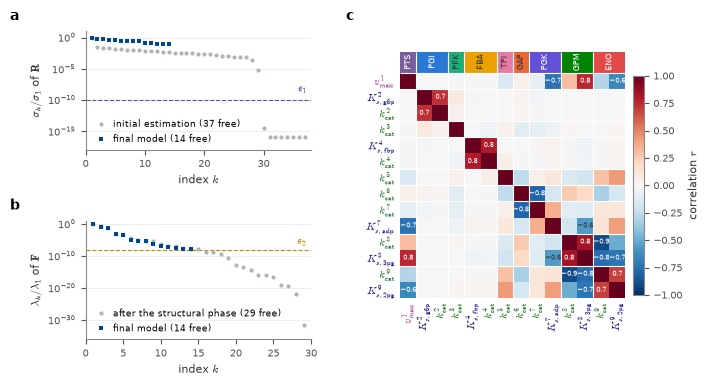

In [7]:
plt.rcdefaults()
plt.rcParams.update(S.RC)
plt.rcParams.update({"mathtext.fontset": "cm"})   # equations in the LaTeX font, as in the main figures

EPS1 = METHOD["structural_tol"]
EPS2 = METHOD["rank_tol"] ** 2   # rank_tol bounds sigma of J; the eigenvalues of F = J^T J are the squares
C_HEADER_LINE = "white"
HEADER_ROWS = 1.3   # height of the reaction header over the correlations, in rows

fig = plt.figure(figsize=(7.2, 4.0))
gs = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.08], wspace=0.38, hspace=0.6)
ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[:, 1])

# ---- (a) structural: singular values of R at the initial estimation and at the final model ----
ax_a.axhline(EPS1, color=RULE_COLOR["structural_zero"], lw=0.8, ls="--")
ax_a.text(len(sigma_initial) + 0.5, EPS1 * 8, "$\\epsilon_1$", ha="right", va="bottom", fontsize=8, color=RULE_COLOR["structural_zero"])
ax_a.semilogy(np.arange(1, len(sigma_initial) + 1), sigma_initial, "o", ms=3.0, mew=0, color=C_LIT, label="initial estimation (%d free)" % len(sigma_initial))
ax_a.semilogy(np.arange(1, len(sigma_final) + 1), sigma_final, "s", ms=3.0, mew=0, color=C_FINAL, label="final model (%d free)" % len(sigma_final))
ax_a.set_ylim(1e-18, 10)
ax_a.set_yticks([1e-15, 1e-10, 1e-5, 1.0])
ax_a.set_xlim(0, len(sigma_initial) + 1)
ax_a.set_xlabel("index $k$")
ax_a.set_ylabel("$\\sigma_k / \\sigma_1$ of $\\mathbf{R}$")
ax_a.grid(axis="y", color=S.GRID, lw=0.5)
ax_a.legend(loc="lower left", frameon=False, fontsize=6.8, handletextpad=0.3, borderaxespad=0.2)

# ---- (b) practical: eigenvalues of F after the structural phase (first practical iteration) and at the final model ----
ax_b.axhline(EPS2, color=RULE_COLOR["svd"], lw=0.8, ls="--")
ax_b.text(len(eigen_by_iteration[first_iteration]) + 0.5, EPS2 * 8, "$\\epsilon_2$", ha="right", va="bottom", fontsize=8, color=RULE_COLOR["svd"])
ax_b.semilogy(np.arange(1, len(eigen_by_iteration[first_iteration]) + 1), eigen_by_iteration[first_iteration], "o", ms=3.0, mew=0, color=C_LIT, label="after the structural phase (%d free)" % len(eigen_by_iteration[first_iteration]))
ax_b.semilogy(np.arange(1, len(eigen_final) + 1), eigen_final, "s", ms=3.0, mew=0, color=C_FINAL, label="final model (%d free)" % len(eigen_final))
ax_b.set_ylim(1e-36, 10)
ax_b.set_yticks([1e-30, 1e-20, 1e-10, 1.0])
ax_b.set_xlim(0, len(eigen_by_iteration[first_iteration]) + 1)
ax_b.set_xlabel("index $k$")
ax_b.set_ylabel("$\\lambda_k / \\lambda_1$ of $\\mathbf{F}$")
ax_b.grid(axis="y", color=S.GRID, lw=0.5)
ax_b.legend(loc="lower left", frameon=False, fontsize=6.8, handletextpad=0.3, borderaxespad=0.2)

# ---- (c) correlations of the free parameters of the final model, under a header with one block per reaction ----
n_free = len(FREE)
im = ax_c.imshow(correlation.to_numpy(float), cmap="RdBu_r", vmin=-1, vmax=1)
header_top = -0.5 - HEADER_ROWS
for r in sorted(set(column_reaction)):
    columns = [j for j, rr in enumerate(column_reaction) if rr == r]
    block_colour = S.REACTION_COLOR[r - 1]
    ax_c.add_patch(Rectangle((columns[0] - 0.5, header_top), len(columns), HEADER_ROWS, color=block_colour, lw=0, clip_on=False))
    ax_c.text(float(np.mean(columns)), header_top + HEADER_ROWS / 2, S.REACTIONS[r - 1][:3], ha="center", va="center", rotation=90, fontsize=5.6, color=text_colour_on(block_colour), clip_on=False)

for j in range(1, n_free):
    if column_reaction[j] != column_reaction[j - 1]:
        ax_c.plot([j - 0.5, j - 0.5], [header_top, n_free - 0.5], color=C_HEADER_LINE, lw=0.8, solid_capstyle="butt", clip_on=False)
        ax_c.plot([-0.5, n_free - 0.5], [j - 0.5, j - 0.5], color=C_HEADER_LINE, lw=0.8, solid_capstyle="butt")

ax_c.plot([-0.5, n_free - 0.5], [-0.5, -0.5], color=C_HEADER_LINE, lw=0.8, solid_capstyle="butt", clip_on=False)
for i in range(n_free):
    for j in range(n_free):
        r_ij = float(correlation.iloc[i, j])
        if i != j and abs(r_ij) >= 0.5:
            ax_c.text(j, i, ("%.1f" % r_ij).replace("-", MINUS), ha="center", va="center", fontsize=5.2, color="white" if abs(r_ij) > 0.6 else S.INK)

ax_c.set_xticks(range(n_free))
ax_c.set_xticklabels([S.label(p) for p in FREE], rotation=90, fontsize=7.5)
ax_c.set_yticks(range(n_free))
ax_c.set_yticklabels([S.label(p) for p in FREE], fontsize=7.5)
for tick, p in zip(ax_c.get_xticklabels(), FREE):
    tick.set_color(TYPE_COLOR[type_of(p)])

for tick, p in zip(ax_c.get_yticklabels(), FREE):
    tick.set_color(TYPE_COLOR[type_of(p)])

ax_c.set_ylim(n_free - 0.5, -0.5)
ax_c.tick_params(length=0)
for sp in ax_c.spines.values():
    sp.set_visible(False)

cb = fig.colorbar(im, ax=ax_c, fraction=0.045, pad=0.03)
cb.set_label("correlation $r$", fontsize=8)
cb.ax.tick_params(labelsize=7)

# panel letters level with the top of each panel (c: with its header)
fig.text(0.02, ax_a.get_position().y1 + 0.02, "a", ha="left", va="bottom", fontsize=10, fontweight="bold")
fig.text(0.02, ax_b.get_position().y1 + 0.02, "b", ha="left", va="bottom", fontsize=10, fontweight="bold")
fig.text(ax_c.get_position().x0 - 0.075, ax_a.get_position().y1 + 0.02, "c", ha="left", va="bottom", fontsize=10, fontweight="bold")

fig.savefig(os.path.join(SUPPLEMENTARY, "figS_final_identifiability.png"), bbox_inches="tight")
fig.savefig(os.path.join(SUPPLEMENTARY, "figS_final_identifiability.pdf"), bbox_inches="tight")

plt.show()

## Fig. S4: parity for every stage

Top row: the 5 LI fluxes, bottom row: the 6 measured metabolites (log-log). Columns: literature model (all 37 parameters at their literature values), initial estimation (37 free), final model, LOOCV held-out predictions. RMSE and $R^2$ (against the per-output mean) from `stage_metrics.csv`.

In [8]:
real = pd.read_csv(path("final", "pred_insample_real.csv"), index_col=0)
pred_literature = pd.read_csv(path("paper_figs_data", "y_literature_inner.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
pred_stage0 = pd.read_csv(path("stage0", "pred_insample_predicted.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
pred_final = pd.read_csv(path("final", "pred_insample_predicted.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
pred_loocv = pd.read_csv(path("loocv", "loocv_pred.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
m = stage_metrics
met_cols = measured_balanced_keys()

def pairs(df, cols):
    yr = real[cols].to_numpy(float).ravel()
    yp = df[cols].to_numpy(float).ravel()
    ok = np.isfinite(yr) & np.isfinite(yp)
    return yp[ok], yr[ok]

f_lit = pairs(pred_literature, LI_FLUX_KEYS)
f_0 = pairs(pred_stage0, LI_FLUX_KEYS)
f_f = pairs(pred_final, LI_FLUX_KEYS)
f_l = pairs(pred_loocv, LI_FLUX_KEYS)
c_lit = pairs(pred_literature, met_cols)
c_0 = pairs(pred_stage0, met_cols)
c_f = pairs(pred_final, met_cols)
c_l = pairs(pred_loocv, met_cols)
FMAX = 8.5
CLO, CHI = 3e-3, 3.0

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


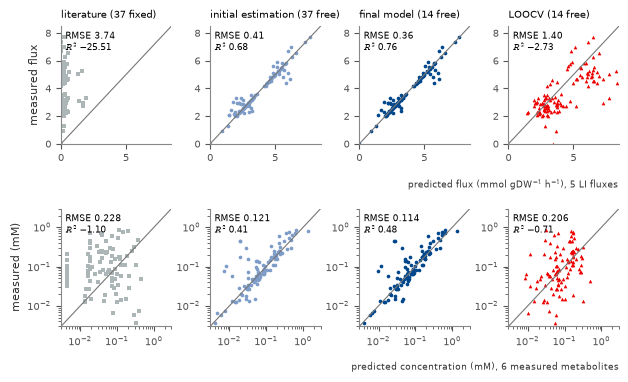

In [9]:
plt.rcdefaults()
plt.rcParams.update(S.RC)
plt.rcParams.update({"mathtext.fontset": "cm"})   # equations in the LaTeX font, as in the main figures

C_LOOCV = "#ED0000"   # LOOCV in the Lancet red of Fig. 2c and 2d (the other model colours are in the helpers cell)

fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.9))
plt.subplots_adjust(wspace=0.35, hspace=0.55)
ax_f1, ax_f2, ax_f3, ax_f4 = axes[0]
ax_c1, ax_c2, ax_c3, ax_c4 = axes[1]

# ---- fluxes ----
ax_f1.plot([0, FMAX], [0, FMAX], color=S.MUTED, lw=0.8)
ax_f1.scatter(f_lit[0], f_lit[1], s=7, marker="s", color=C_LIT, lw=0)
ax_f1.set_xlim(0, FMAX)
ax_f1.set_ylim(0, FMAX)
ax_f1.set_title("literature (%d fixed)" % len(ALL_PARAMS), fontsize=7.5)
ax_f1.text(0.04, 0.96, ("RMSE %.2f\n$R^2$ %.2f" % (m.loc["literature", "rmse_flux_li"], m.loc["literature", "r2_flux_li_permean"])).replace("-", MINUS), transform=ax_f1.transAxes, va="top", fontsize=6.2)
ax_f1.set_ylabel("measured flux")

ax_f2.plot([0, FMAX], [0, FMAX], color=S.MUTED, lw=0.8)
ax_f2.scatter(f_0[0], f_0[1], s=7, color=C_INITIAL, lw=0)
ax_f2.set_xlim(0, FMAX)
ax_f2.set_ylim(0, FMAX)
ax_f2.set_title("initial estimation (%d free)" % len(ALL_PARAMS), fontsize=7.5)
ax_f2.text(0.04, 0.96, ("RMSE %.2f\n$R^2$ %.2f" % (m.loc["stage0", "rmse_flux_li"], m.loc["stage0", "r2_flux_li_permean"])).replace("-", MINUS), transform=ax_f2.transAxes, va="top", fontsize=6.2)

ax_f3.plot([0, FMAX], [0, FMAX], color=S.MUTED, lw=0.8)
ax_f3.scatter(f_f[0], f_f[1], s=7, color=C_FINAL, lw=0)
ax_f3.set_xlim(0, FMAX)
ax_f3.set_ylim(0, FMAX)
ax_f3.set_title("final model (%d free)" % len(FREE), fontsize=7.5)
ax_f3.text(0.04, 0.96, ("RMSE %.2f\n$R^2$ %.2f" % (m.loc["final", "rmse_flux_li"], m.loc["final", "r2_flux_li_permean"])).replace("-", MINUS), transform=ax_f3.transAxes, va="top", fontsize=6.2)

ax_f4.plot([0, FMAX], [0, FMAX], color=S.MUTED, lw=0.8)
ax_f4.scatter(f_l[0], f_l[1], s=7, marker="^", color=C_LOOCV, lw=0)
ax_f4.set_xlim(0, FMAX)
ax_f4.set_ylim(0, FMAX)
ax_f4.set_title("LOOCV (%d free)" % len(FREE), fontsize=7.5)
ax_f4.text(0.04, 0.96, ("RMSE %.2f\n$R^2$ %.2f" % (m.loc["loocv", "rmse_flux_li"], m.loc["loocv", "r2_flux_li_permean"])).replace("-", MINUS), transform=ax_f4.transAxes, va="top", fontsize=6.2)
ax_f4.text(1.0, -0.3, "predicted flux (mmol gDW$^{-1}$ h$^{-1}$), 5 LI fluxes", transform=ax_f4.transAxes, ha="right", va="top", fontsize=6.8, color=S.INK)

# ---- metabolites ----
ax_c1.plot([CLO, CHI], [CLO, CHI], color=S.MUTED, lw=0.8)
ax_c1.scatter(c_lit[0], c_lit[1], s=7, marker="s", color=C_LIT, lw=0)
ax_c1.set_xscale("log")
ax_c1.set_yscale("log")
ax_c1.set_xlim(CLO, CHI)
ax_c1.set_ylim(CLO, CHI)
ax_c1.text(0.04, 0.96, ("RMSE %.3f\n$R^2$ %.2f" % (m.loc["literature", "rmse_met"], m.loc["literature", "r2_met_permean"])).replace("-", MINUS), transform=ax_c1.transAxes, va="top", fontsize=6.2)
ax_c1.set_ylabel("measured (mM)")

ax_c2.plot([CLO, CHI], [CLO, CHI], color=S.MUTED, lw=0.8)
ax_c2.scatter(c_0[0], c_0[1], s=7, color=C_INITIAL, lw=0)
ax_c2.set_xscale("log")
ax_c2.set_yscale("log")
ax_c2.set_xlim(CLO, CHI)
ax_c2.set_ylim(CLO, CHI)
ax_c2.text(0.04, 0.96, ("RMSE %.3f\n$R^2$ %.2f" % (m.loc["stage0", "rmse_met"], m.loc["stage0", "r2_met_permean"])).replace("-", MINUS), transform=ax_c2.transAxes, va="top", fontsize=6.2)

ax_c3.plot([CLO, CHI], [CLO, CHI], color=S.MUTED, lw=0.8)
ax_c3.scatter(c_f[0], c_f[1], s=7, color=C_FINAL, lw=0)
ax_c3.set_xscale("log")
ax_c3.set_yscale("log")
ax_c3.set_xlim(CLO, CHI)
ax_c3.set_ylim(CLO, CHI)
ax_c3.text(0.04, 0.96, ("RMSE %.3f\n$R^2$ %.2f" % (m.loc["final", "rmse_met"], m.loc["final", "r2_met_permean"])).replace("-", MINUS), transform=ax_c3.transAxes, va="top", fontsize=6.2)

ax_c4.plot([CLO, CHI], [CLO, CHI], color=S.MUTED, lw=0.8)
ax_c4.scatter(c_l[0], c_l[1], s=7, marker="^", color=C_LOOCV, lw=0)
ax_c4.set_xscale("log")
ax_c4.set_yscale("log")
ax_c4.set_xlim(CLO, CHI)
ax_c4.set_ylim(CLO, CHI)
ax_c4.text(0.04, 0.96, ("RMSE %.3f\n$R^2$ %.2f" % (m.loc["loocv", "rmse_met"], m.loc["loocv", "r2_met_permean"])).replace("-", MINUS), transform=ax_c4.transAxes, va="top", fontsize=6.2)
ax_c4.text(1.0, -0.3, "predicted concentration (mM), 6 measured metabolites", transform=ax_c4.transAxes, ha="right", va="top", fontsize=6.8, color=S.INK)

fig.savefig(os.path.join(SUPPLEMENTARY, "figS_parity_stages.png"), bbox_inches="tight")
fig.savefig(os.path.join(SUPPLEMENTARY, "figS_parity_stages.pdf"), bbox_inches="tight")

plt.show()

## Fig. S5: parameter evolution

All 37 parameter values grouped by reaction (a band and a strip in the reaction colours of Fig. 2a; names coloured by parameter type): literature, initial estimation, final model, joined by a grey line over the range they cover. Free parameters of the final model are filled diamonds; fixed ones are open diamonds (the value at which the parameter was fixed: its estimate in the fit the decision was taken on). The status on the right is "free" or the rule that fixed the parameter with its iteration, in the rule colours of Fig. S2.

In [10]:
fix = pd.read_csv(path("reduction", "fixing_log.csv"))
fixed_decisions = fix[fix["action"] == "fixed"].set_index("param")
params = list(ALL_PARAMS)   # model order: grouped by reaction
REACTION_GAP = 0.8   # extra space between the rows of two reactions
y = np.arange(len(params), dtype=float)
for i, p in enumerate(params):
    y[i] += REACTION_GAP * (S.reaction_of(p) - 1)

is_free = np.array([p in FREE for p in params])
v_lit = np.array([literature[p] for p in params], float)
v_0 = np.array([th0[p] for p in params], float)
v_f = np.array([thf[p] for p in params], float)

# status of every parameter: free, or the rule (and practical iteration) that fixed it, with its colour
status_text = []
status_color = []
for p in params:
    if p not in fixed_decisions.index:
        status_text.append("free")
        status_color.append(C_FINAL)
    elif fixed_decisions.loc[p, "rule"] == "structural_zero":
        status_text.append("structural zero")
        status_color.append(RULE_COLOR["structural_zero"])
    elif fixed_decisions.loc[p, "rule"] == "svd":
        status_text.append("rank of $\\mathbf{F}$, it. %d" % fixed_decisions.loc[p, "iter"])
        status_color.append(RULE_COLOR["svd"])
    else:
        status_text.append("$|r| > %g$ with %s, it. %d" % (METHOD["corr_threshold"], S.label(fixed_decisions.loc[p, "partner"]), fixed_decisions.loc[p, "iter"]))
        status_color.append(RULE_COLOR["correlation"])

# first and last row of every reaction, for its band and its name
rxn_rows = []
for r in range(1, 10):
    rows_of_reaction = np.array([S.reaction_of(p) == r for p in params])
    rxn_rows.append((float(np.min(y[rows_of_reaction])), float(np.max(y[rows_of_reaction]))))

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


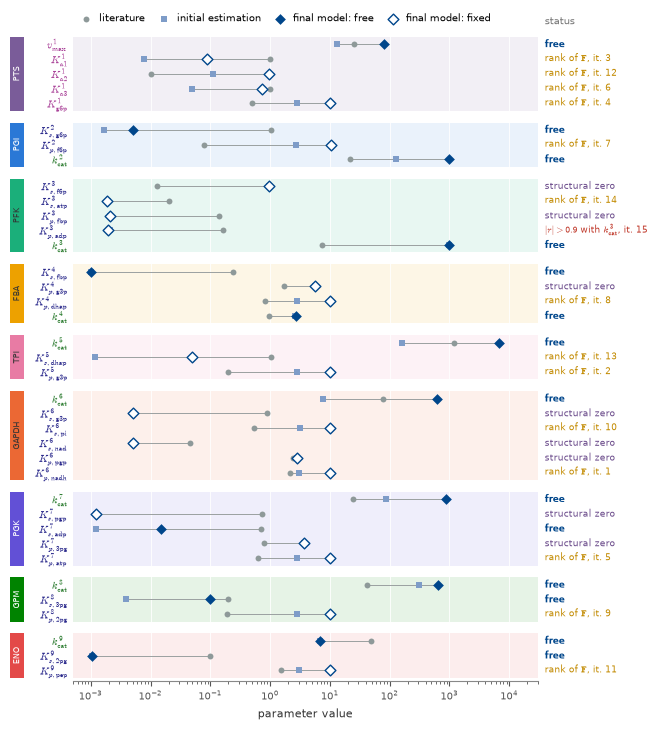

In [11]:
plt.rcdefaults()
plt.rcParams.update(S.RC)
plt.rcParams.update({"mathtext.fontset": "cm"})   # equations in the LaTeX font, as in the main figures

C_LIT_MARKER = "#8E9999"   # the literature grey, a little darker so that it shows on the reaction bands
STRIP_X0 = -0.135          # the reaction strips sit left of the parameter names (axes fraction)
STRIP_W = 0.03

fig, ax = plt.subplots(figsize=(6.0, 8.4))
blend = ax.get_yaxis_transform()   # x in axes fraction, y in data

# ---- one light band per reaction behind its rows, and a strip with the reaction name left of the parameter names ----
for r in range(1, 10):
    top, bottom = rxn_rows[r - 1]
    colour = S.REACTION_COLOR[r - 1]
    ax.axhspan(top - 0.5, bottom + 0.5, color=lighter(colour, 0.9), lw=0, zorder=0)
    ax.add_patch(Rectangle((STRIP_X0, top - 0.5), STRIP_W, bottom - top + 1.0, transform=blend, color=colour, lw=0, clip_on=False))
    ax.text(STRIP_X0 + STRIP_W / 2, (top + bottom) / 2, S.REACTIONS[r - 1], transform=blend, rotation=90, ha="center", va="center", fontsize=6.0, color=text_colour_on(colour), clip_on=False)

# ---- range covered by the three values of each parameter, then the values ----
for yy, a, b, c in zip(y, v_lit, v_0, v_f):
    ax.plot([min(a, b, c), max(a, b, c)], [yy, yy], color="#9aa0a0", lw=0.7, zorder=1)

ax.scatter(v_lit, y, s=18, marker="o", color=C_LIT_MARKER, lw=0, zorder=2, label="literature")
ax.scatter(v_0, y, s=18, marker="s", color=C_INITIAL, lw=0, zorder=3, label="initial estimation")
ax.scatter(v_f[is_free], y[is_free], s=30, marker="D", color=C_FINAL, lw=0, zorder=4, label="final model: free")
ax.scatter(v_f[~is_free], y[~is_free], s=30, marker="D", facecolors="white", edgecolors=C_FINAL, linewidths=1.0, zorder=4, label="final model: fixed")

ax.set_xscale("log")
ax.set_xlim(5e-4, 3e4)
ax.set_yticks(y)
ax.set_yticklabels([S.label(p) for p in params], fontsize=7.5)
for tick, p in zip(ax.get_yticklabels(), params):
    tick.set_color(TYPE_COLOR[type_of(p)])

ax.set_ylim(y.max() + 0.7, -0.7)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color="white", lw=0.6)
ax.set_axisbelow(True)   # the grid lines between the reaction bands and the values
ax.set_xlabel("parameter value")

# ---- status of every parameter, right of the panel, in the colour of the rule that fixed it ----
for yy, txt, colour, free_row in zip(y, status_text, status_color, is_free):
    ax.text(1.015, yy, txt, transform=blend, fontsize=6.8, va="center", ha="left", color=colour, fontweight="bold" if free_row else "normal", clip_on=False)

ax.text(1.015, -1.2, "status", transform=blend, fontsize=7, ha="left", va="bottom", color=S.MUTED, clip_on=False)
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.01), ncol=4, frameon=False, fontsize=7, handletextpad=0.3, columnspacing=1.0, borderaxespad=0.0)

fig.savefig(os.path.join(SUPPLEMENTARY, "figS_parameter_evolution.png"), bbox_inches="tight")
fig.savefig(os.path.join(SUPPLEMENTARY, "figS_parameter_evolution.pdf"), bbox_inches="tight")

plt.show()

## Fig. S6: bootstrap distributions of the free parameters

One panel per free parameter: $x = \log_{10}(\theta^* / \hat\theta)$ over the converged resamples, the estimate (black line) and the 95% percentile interval (2.5 to 97.5 percentiles, shaded); the title gives the ratio $p_{97.5}/p_{2.5}$ (practically identifiable by the bootstrap if at most `bootstrap_ci_ratio` and the interval does not reach a parameter bound; "bound" marks an interval that reaches one) and the colour the verdict of the bootstrap alone.

In [12]:
if len(FREE) != 14:
    raise ValueError("figS_bootstrap_all and figS_profiles_all are laid out for 14 free parameters, this run has %d: %s" % (len(FREE), FREE))

boot = pd.read_csv(path("bootstrap", "bootstrap_theta.csv"))
boot = boot[boot["converged"]].reset_index(drop=True)
B = {}
for p in FREE:
    estimate = float(thf[p])
    d = np.log10(boot[p].to_numpy(float) / estimate)
    q_lo = min(np.percentile(d, 0.5), 0.0)
    q_hi = max(np.percentile(d, 99.5), 0.0)
    pad = max(0.05 * (q_hi - q_lo), 1e-4)
    q_lo = q_lo - pad
    q_hi = q_hi + pad
    title = S.label(p) + "  ratio %.3g" % float(bootstrap_summary.loc[p, "ci_ratio_97.5_over_2.5"])
    if bool(bootstrap_summary.loc[p, "interval_reaches_bound"]):
        title = title + ", bound"
    B[p] = {"d": d,
            "title": title,
            "lo": np.log10(float(bootstrap_summary.loc[p, "p2.5"]) / estimate),
            "hi": np.log10(float(bootstrap_summary.loc[p, "p97.5"]) / estimate),
            "bins": np.linspace(q_lo, q_hi, 40),
            "xlim": (q_lo, q_hi),
            "color": C_IDENTIFIABLE if bool(bootstrap_summary.loc[p, "practically_identifiable"]) else C_NOT_IDENTIFIABLE}

# colour = the verdict of the bootstrap alone (the profiles have their own figure)
BOOT_LEGEND = [("practically identifiable (bootstrap)", C_IDENTIFIABLE), ("not identifiable (bootstrap)", C_NOT_IDENTIFIABLE)]

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


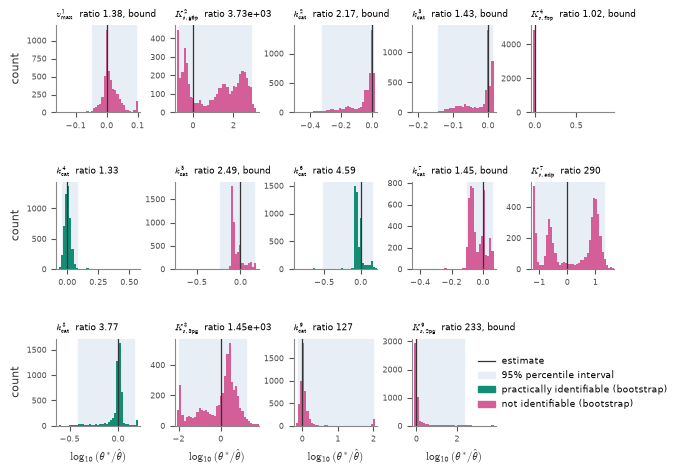

In [13]:
plt.rcdefaults()
plt.rcParams.update(S.RC)
plt.rcParams.update({"mathtext.fontset": "cm"})   # equations in the LaTeX font, as in the main figures

fig, axes = plt.subplots(3, 5, figsize=(7.2, 5.2))
plt.subplots_adjust(wspace=0.42, hspace=0.8)
ax_a, ax_b, ax_c, ax_d, ax_e = axes[0]
ax_f, ax_g, ax_h, ax_i, ax_j = axes[1]
ax_k, ax_l, ax_m, ax_n, ax_leg = axes[2]

# ---- panel 1: FREE[0] ----
ax_a.axvspan(B[FREE[0]]["lo"], B[FREE[0]]["hi"], color="#e8eef5", zorder=0)
ax_a.hist(B[FREE[0]]["d"], bins=B[FREE[0]]["bins"], color=B[FREE[0]]["color"], zorder=2)
ax_a.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_a.set_xlim(*B[FREE[0]]["xlim"])
ax_a.set_title(B[FREE[0]]["title"], fontsize=6.4)
ax_a.tick_params(axis="x", labelsize=5.6)
ax_a.tick_params(axis="y", labelsize=5.6)

# ---- panel 2: FREE[1] ----
ax_b.axvspan(B[FREE[1]]["lo"], B[FREE[1]]["hi"], color="#e8eef5", zorder=0)
ax_b.hist(B[FREE[1]]["d"], bins=B[FREE[1]]["bins"], color=B[FREE[1]]["color"], zorder=2)
ax_b.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_b.set_xlim(*B[FREE[1]]["xlim"])
ax_b.set_title(B[FREE[1]]["title"], fontsize=6.4)
ax_b.tick_params(axis="x", labelsize=5.6)
ax_b.tick_params(axis="y", labelsize=5.6)

# ---- panel 3: FREE[2] ----
ax_c.axvspan(B[FREE[2]]["lo"], B[FREE[2]]["hi"], color="#e8eef5", zorder=0)
ax_c.hist(B[FREE[2]]["d"], bins=B[FREE[2]]["bins"], color=B[FREE[2]]["color"], zorder=2)
ax_c.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_c.set_xlim(*B[FREE[2]]["xlim"])
ax_c.set_title(B[FREE[2]]["title"], fontsize=6.4)
ax_c.tick_params(axis="x", labelsize=5.6)
ax_c.tick_params(axis="y", labelsize=5.6)

# ---- panel 4: FREE[3] ----
ax_d.axvspan(B[FREE[3]]["lo"], B[FREE[3]]["hi"], color="#e8eef5", zorder=0)
ax_d.hist(B[FREE[3]]["d"], bins=B[FREE[3]]["bins"], color=B[FREE[3]]["color"], zorder=2)
ax_d.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_d.set_xlim(*B[FREE[3]]["xlim"])
ax_d.set_title(B[FREE[3]]["title"], fontsize=6.4)
ax_d.tick_params(axis="x", labelsize=5.6)
ax_d.tick_params(axis="y", labelsize=5.6)

# ---- panel 5: FREE[4] ----
ax_e.axvspan(B[FREE[4]]["lo"], B[FREE[4]]["hi"], color="#e8eef5", zorder=0)
ax_e.hist(B[FREE[4]]["d"], bins=B[FREE[4]]["bins"], color=B[FREE[4]]["color"], zorder=2)
ax_e.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_e.set_xlim(*B[FREE[4]]["xlim"])
ax_e.set_title(B[FREE[4]]["title"], fontsize=6.4)
ax_e.tick_params(axis="x", labelsize=5.6)
ax_e.tick_params(axis="y", labelsize=5.6)

# ---- panel 6: FREE[5] ----
ax_f.axvspan(B[FREE[5]]["lo"], B[FREE[5]]["hi"], color="#e8eef5", zorder=0)
ax_f.hist(B[FREE[5]]["d"], bins=B[FREE[5]]["bins"], color=B[FREE[5]]["color"], zorder=2)
ax_f.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_f.set_xlim(*B[FREE[5]]["xlim"])
ax_f.set_title(B[FREE[5]]["title"], fontsize=6.4)
ax_f.tick_params(axis="x", labelsize=5.6)
ax_f.tick_params(axis="y", labelsize=5.6)

# ---- panel 7: FREE[6] ----
ax_g.axvspan(B[FREE[6]]["lo"], B[FREE[6]]["hi"], color="#e8eef5", zorder=0)
ax_g.hist(B[FREE[6]]["d"], bins=B[FREE[6]]["bins"], color=B[FREE[6]]["color"], zorder=2)
ax_g.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_g.set_xlim(*B[FREE[6]]["xlim"])
ax_g.set_title(B[FREE[6]]["title"], fontsize=6.4)
ax_g.tick_params(axis="x", labelsize=5.6)
ax_g.tick_params(axis="y", labelsize=5.6)

# ---- panel 8: FREE[7] ----
ax_h.axvspan(B[FREE[7]]["lo"], B[FREE[7]]["hi"], color="#e8eef5", zorder=0)
ax_h.hist(B[FREE[7]]["d"], bins=B[FREE[7]]["bins"], color=B[FREE[7]]["color"], zorder=2)
ax_h.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_h.set_xlim(*B[FREE[7]]["xlim"])
ax_h.set_title(B[FREE[7]]["title"], fontsize=6.4)
ax_h.tick_params(axis="x", labelsize=5.6)
ax_h.tick_params(axis="y", labelsize=5.6)

# ---- panel 9: FREE[8] ----
ax_i.axvspan(B[FREE[8]]["lo"], B[FREE[8]]["hi"], color="#e8eef5", zorder=0)
ax_i.hist(B[FREE[8]]["d"], bins=B[FREE[8]]["bins"], color=B[FREE[8]]["color"], zorder=2)
ax_i.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_i.set_xlim(*B[FREE[8]]["xlim"])
ax_i.set_title(B[FREE[8]]["title"], fontsize=6.4)
ax_i.tick_params(axis="x", labelsize=5.6)
ax_i.tick_params(axis="y", labelsize=5.6)

# ---- panel 10: FREE[9] ----
ax_j.axvspan(B[FREE[9]]["lo"], B[FREE[9]]["hi"], color="#e8eef5", zorder=0)
ax_j.hist(B[FREE[9]]["d"], bins=B[FREE[9]]["bins"], color=B[FREE[9]]["color"], zorder=2)
ax_j.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_j.set_xlim(*B[FREE[9]]["xlim"])
ax_j.set_title(B[FREE[9]]["title"], fontsize=6.4)
ax_j.tick_params(axis="x", labelsize=5.6)
ax_j.tick_params(axis="y", labelsize=5.6)

# ---- panel 11: FREE[10] ----
ax_k.axvspan(B[FREE[10]]["lo"], B[FREE[10]]["hi"], color="#e8eef5", zorder=0)
ax_k.hist(B[FREE[10]]["d"], bins=B[FREE[10]]["bins"], color=B[FREE[10]]["color"], zorder=2)
ax_k.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_k.set_xlim(*B[FREE[10]]["xlim"])
ax_k.set_title(B[FREE[10]]["title"], fontsize=6.4)
ax_k.tick_params(axis="x", labelsize=5.6)
ax_k.tick_params(axis="y", labelsize=5.6)

# ---- panel 12: FREE[11] ----
ax_l.axvspan(B[FREE[11]]["lo"], B[FREE[11]]["hi"], color="#e8eef5", zorder=0)
ax_l.hist(B[FREE[11]]["d"], bins=B[FREE[11]]["bins"], color=B[FREE[11]]["color"], zorder=2)
ax_l.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_l.set_xlim(*B[FREE[11]]["xlim"])
ax_l.set_title(B[FREE[11]]["title"], fontsize=6.4)
ax_l.tick_params(axis="x", labelsize=5.6)
ax_l.tick_params(axis="y", labelsize=5.6)

# ---- panel 13: FREE[12] ----
ax_m.axvspan(B[FREE[12]]["lo"], B[FREE[12]]["hi"], color="#e8eef5", zorder=0)
ax_m.hist(B[FREE[12]]["d"], bins=B[FREE[12]]["bins"], color=B[FREE[12]]["color"], zorder=2)
ax_m.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_m.set_xlim(*B[FREE[12]]["xlim"])
ax_m.set_title(B[FREE[12]]["title"], fontsize=6.4)
ax_m.tick_params(axis="x", labelsize=5.6)
ax_m.tick_params(axis="y", labelsize=5.6)

# ---- panel 14: FREE[13] ----
ax_n.axvspan(B[FREE[13]]["lo"], B[FREE[13]]["hi"], color="#e8eef5", zorder=0)
ax_n.hist(B[FREE[13]]["d"], bins=B[FREE[13]]["bins"], color=B[FREE[13]]["color"], zorder=2)
ax_n.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_n.set_xlim(*B[FREE[13]]["xlim"])
ax_n.set_title(B[FREE[13]]["title"], fontsize=6.4)
ax_n.tick_params(axis="x", labelsize=5.6)
ax_n.tick_params(axis="y", labelsize=5.6)

# ---- legend cell ----
legend_handles = [Line2D([0], [0], color=S.INK, lw=0.9, label="estimate"),
                  Patch(color="#e8eef5", label="95% percentile interval")]
for name, colour in BOOT_LEGEND:
    legend_handles.append(Patch(color=colour, label=name))

ax_leg.axis("off")
ax_leg.legend(handles=legend_handles, loc="center", frameon=False, fontsize=6.2)
ax_a.set_ylabel("count")
ax_f.set_ylabel("count")
ax_k.set_ylabel("count")
ax_k.set_xlabel("$\\log_{10}(\\theta^{*} / \\hat{\\theta})$")
ax_l.set_xlabel("$\\log_{10}(\\theta^{*} / \\hat{\\theta})$")
ax_m.set_xlabel("$\\log_{10}(\\theta^{*} / \\hat{\\theta})$")
ax_n.set_xlabel("$\\log_{10}(\\theta^{*} / \\hat{\\theta})$")

fig.savefig(os.path.join(SUPPLEMENTARY, "figS_bootstrap_all.png"), bbox_inches="tight")
fig.savefig(os.path.join(SUPPLEMENTARY, "figS_bootstrap_all.pdf"), bbox_inches="tight")

plt.show()

## Fig. S7: profile likelihoods of the free parameters

Re-optimised profiles ($\pm$ `profile_span` decades, `profile_points` points on each side; every point fixes the parameter and re-optimises the other free parameters, warm started at the previous point): objective minus the objective of the final fit, with the 95% threshold $\chi^2_{0.95,1}/(2N)$. The panels share both axes and show the profile class in the title and the colour (as in Fig. 2e): identifiable (both arms cross the threshold), one-sided (one arm crosses), flat (none crosses). The first point of each arm is the re-optimised fit at the estimate; it lies slightly above the objective of the final fit.

In [14]:
prof = pd.read_csv(path("profiles", "profiles_all.csv"))
thr = json.load(open(path("profiles", "profile_thresholds.json")))
obj_hat = float(thr["obj_hat"])
lr = float(thr["lr_threshold"])
PROFILE_COLOR = {"identifiable": C_IDENTIFIABLE, "wide": C_ONE_SIDED, "one_sided": C_ONE_SIDED, "flat": C_NOT_IDENTIFIABLE}
P = {}
for p in FREE:
    d = prof[prof["param"] == p].sort_values("log10_offset")
    P[p] = {"x": d["log10_offset"].to_numpy(float),
            "y": d["obj"].to_numpy(float) - obj_hat,
            "cls": profile_summary.loc[p, "profile_class"].replace("_", "-"),
            "color": PROFILE_COLOR[profile_summary.loc[p, "profile_class"]]}

YMAX = 0.4
XMAX = METHOD["profile_span"] + 0.02

# colour = the profile class alone (the bootstrap has its own figure)
PROFILE_LEGEND = []
for profile_class in ["identifiable", "wide", "one_sided", "flat"]:
    if (profile_summary.loc[FREE, "profile_class"] == profile_class).any():
        PROFILE_LEGEND.append((profile_class.replace("_", "-"), PROFILE_COLOR[profile_class]))

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


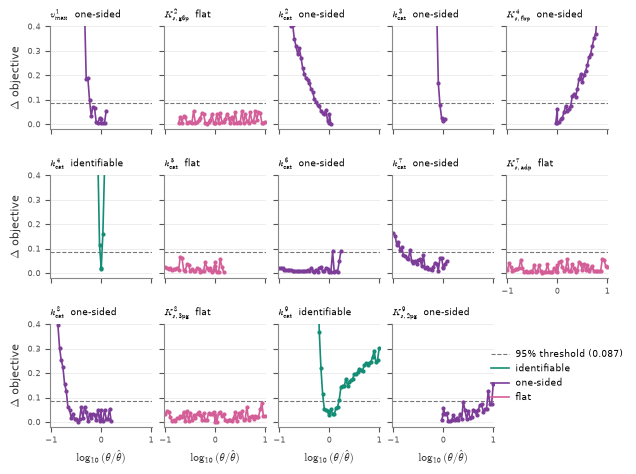

In [15]:
plt.rcdefaults()
plt.rcParams.update(S.RC)
plt.rcParams.update({"mathtext.fontset": "cm"})   # equations in the LaTeX font, as in the main figures

fig, axes = plt.subplots(3, 5, figsize=(7.2, 5.2), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.12, hspace=0.45)
ax_a, ax_b, ax_c, ax_d, ax_e = axes[0]
ax_f, ax_g, ax_h, ax_i, ax_j = axes[1]
ax_k, ax_l, ax_m, ax_n, ax_leg = axes[2]

# ---- panel 1: FREE[0] ----
ax_a.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_a.plot(P[FREE[0]]["x"], np.clip(P[FREE[0]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[0]]["color"])
ax_a.set_ylim(-0.02, YMAX)
ax_a.set_xlim(-XMAX, XMAX)
ax_a.set_title(S.label(FREE[0]) + "  " + P[FREE[0]]["cls"], fontsize=6.8)
ax_a.grid(axis="y", color=S.GRID, lw=0.5)
ax_a.tick_params(labelsize=5.6)

# ---- panel 2: FREE[1] ----
ax_b.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_b.plot(P[FREE[1]]["x"], np.clip(P[FREE[1]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[1]]["color"])
ax_b.set_ylim(-0.02, YMAX)
ax_b.set_xlim(-XMAX, XMAX)
ax_b.set_title(S.label(FREE[1]) + "  " + P[FREE[1]]["cls"], fontsize=6.8)
ax_b.grid(axis="y", color=S.GRID, lw=0.5)
ax_b.tick_params(labelsize=5.6)

# ---- panel 3: FREE[2] ----
ax_c.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_c.plot(P[FREE[2]]["x"], np.clip(P[FREE[2]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[2]]["color"])
ax_c.set_ylim(-0.02, YMAX)
ax_c.set_xlim(-XMAX, XMAX)
ax_c.set_title(S.label(FREE[2]) + "  " + P[FREE[2]]["cls"], fontsize=6.8)
ax_c.grid(axis="y", color=S.GRID, lw=0.5)
ax_c.tick_params(labelsize=5.6)

# ---- panel 4: FREE[3] ----
ax_d.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_d.plot(P[FREE[3]]["x"], np.clip(P[FREE[3]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[3]]["color"])
ax_d.set_ylim(-0.02, YMAX)
ax_d.set_xlim(-XMAX, XMAX)
ax_d.set_title(S.label(FREE[3]) + "  " + P[FREE[3]]["cls"], fontsize=6.8)
ax_d.grid(axis="y", color=S.GRID, lw=0.5)
ax_d.tick_params(labelsize=5.6)

# ---- panel 5: FREE[4] ----
ax_e.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_e.plot(P[FREE[4]]["x"], np.clip(P[FREE[4]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[4]]["color"])
ax_e.set_ylim(-0.02, YMAX)
ax_e.set_xlim(-XMAX, XMAX)
ax_e.set_title(S.label(FREE[4]) + "  " + P[FREE[4]]["cls"], fontsize=6.8)
ax_e.grid(axis="y", color=S.GRID, lw=0.5)
ax_e.tick_params(labelsize=5.6)

# ---- panel 6: FREE[5] ----
ax_f.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_f.plot(P[FREE[5]]["x"], np.clip(P[FREE[5]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[5]]["color"])
ax_f.set_ylim(-0.02, YMAX)
ax_f.set_xlim(-XMAX, XMAX)
ax_f.set_title(S.label(FREE[5]) + "  " + P[FREE[5]]["cls"], fontsize=6.8)
ax_f.grid(axis="y", color=S.GRID, lw=0.5)
ax_f.tick_params(labelsize=5.6)

# ---- panel 7: FREE[6] ----
ax_g.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_g.plot(P[FREE[6]]["x"], np.clip(P[FREE[6]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[6]]["color"])
ax_g.set_ylim(-0.02, YMAX)
ax_g.set_xlim(-XMAX, XMAX)
ax_g.set_title(S.label(FREE[6]) + "  " + P[FREE[6]]["cls"], fontsize=6.8)
ax_g.grid(axis="y", color=S.GRID, lw=0.5)
ax_g.tick_params(labelsize=5.6)

# ---- panel 8: FREE[7] ----
ax_h.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_h.plot(P[FREE[7]]["x"], np.clip(P[FREE[7]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[7]]["color"])
ax_h.set_ylim(-0.02, YMAX)
ax_h.set_xlim(-XMAX, XMAX)
ax_h.set_title(S.label(FREE[7]) + "  " + P[FREE[7]]["cls"], fontsize=6.8)
ax_h.grid(axis="y", color=S.GRID, lw=0.5)
ax_h.tick_params(labelsize=5.6)

# ---- panel 9: FREE[8] ----
ax_i.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_i.plot(P[FREE[8]]["x"], np.clip(P[FREE[8]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[8]]["color"])
ax_i.set_ylim(-0.02, YMAX)
ax_i.set_xlim(-XMAX, XMAX)
ax_i.set_title(S.label(FREE[8]) + "  " + P[FREE[8]]["cls"], fontsize=6.8)
ax_i.grid(axis="y", color=S.GRID, lw=0.5)
ax_i.tick_params(labelsize=5.6)

# ---- panel 10: FREE[9] ----
ax_j.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_j.plot(P[FREE[9]]["x"], np.clip(P[FREE[9]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[9]]["color"])
ax_j.set_ylim(-0.02, YMAX)
ax_j.set_xlim(-XMAX, XMAX)
ax_j.set_title(S.label(FREE[9]) + "  " + P[FREE[9]]["cls"], fontsize=6.8)
ax_j.grid(axis="y", color=S.GRID, lw=0.5)
ax_j.tick_params(labelsize=5.6)

# ---- panel 11: FREE[10] ----
ax_k.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_k.plot(P[FREE[10]]["x"], np.clip(P[FREE[10]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[10]]["color"])
ax_k.set_ylim(-0.02, YMAX)
ax_k.set_xlim(-XMAX, XMAX)
ax_k.set_title(S.label(FREE[10]) + "  " + P[FREE[10]]["cls"], fontsize=6.8)
ax_k.grid(axis="y", color=S.GRID, lw=0.5)
ax_k.tick_params(labelsize=5.6)

# ---- panel 12: FREE[11] ----
ax_l.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_l.plot(P[FREE[11]]["x"], np.clip(P[FREE[11]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[11]]["color"])
ax_l.set_ylim(-0.02, YMAX)
ax_l.set_xlim(-XMAX, XMAX)
ax_l.set_title(S.label(FREE[11]) + "  " + P[FREE[11]]["cls"], fontsize=6.8)
ax_l.grid(axis="y", color=S.GRID, lw=0.5)
ax_l.tick_params(labelsize=5.6)

# ---- panel 13: FREE[12] ----
ax_m.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_m.plot(P[FREE[12]]["x"], np.clip(P[FREE[12]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[12]]["color"])
ax_m.set_ylim(-0.02, YMAX)
ax_m.set_xlim(-XMAX, XMAX)
ax_m.set_title(S.label(FREE[12]) + "  " + P[FREE[12]]["cls"], fontsize=6.8)
ax_m.grid(axis="y", color=S.GRID, lw=0.5)
ax_m.tick_params(labelsize=5.6)

# ---- panel 14: FREE[13] ----
ax_n.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_n.plot(P[FREE[13]]["x"], np.clip(P[FREE[13]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[13]]["color"])
ax_n.set_ylim(-0.02, YMAX)
ax_n.set_xlim(-XMAX, XMAX)
ax_n.set_title(S.label(FREE[13]) + "  " + P[FREE[13]]["cls"], fontsize=6.8)
ax_n.grid(axis="y", color=S.GRID, lw=0.5)
ax_n.tick_params(labelsize=5.6)

# ---- legend cell ----
legend_handles = [Line2D([0], [0], color=S.MUTED, lw=0.8, ls="--", label="95%% threshold (%.3f)" % lr)]
for name, colour in PROFILE_LEGEND:
    legend_handles.append(Line2D([0], [0], color=colour, lw=1.2, label=name))

ax_leg.axis("off")
ax_leg.legend(handles=legend_handles, loc="center", frameon=False, fontsize=6.2)
ax_a.set_ylabel("$\\Delta$ objective")
ax_f.set_ylabel("$\\Delta$ objective")
ax_k.set_ylabel("$\\Delta$ objective")
ax_k.set_xlabel("$\\log_{10}(\\theta / \\hat{\\theta})$")
ax_l.set_xlabel("$\\log_{10}(\\theta / \\hat{\\theta})$")
ax_m.set_xlabel("$\\log_{10}(\\theta / \\hat{\\theta})$")
ax_n.set_xlabel("$\\log_{10}(\\theta / \\hat{\\theta})$")
ax_j.tick_params(labelbottom=True)

fig.savefig(os.path.join(SUPPLEMENTARY, "figS_profiles_all.png"), bbox_inches="tight")
fig.savefig(os.path.join(SUPPLEMENTARY, "figS_profiles_all.pdf"), bbox_inches="tight")

plt.show()